# Create predictand dataset

To plug into fully interacted Carleton et al. model: 
- Long-run temperature: From tassumpoly, degree 1, / 365
- Population: From input dataset + SSP outputs
- GDP PC: From input dataset + SSP outputs

(the SSP outputs start at 2010, which may be too late for GWL1, and definitely 0.61 - so we take population and GDP pc from the mortality data dataset)

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import re
import os
import glob

from funcs_support import get_params, get_filepaths, utility_save
dir_list = get_params()

In [ ]:
from distributed import Client
# Start dask client
client = Client()
display(client)

In [3]:
# Get tassumpoly, aggregated to impact regions
df = get_filepaths(source_dir = 'proc')
df = df.query('varname == "tassumpoly" and gwl == "ALLGWLs" and suffix == "regions" and freq == "agg"')

In [4]:
# Load Carleton et al. "Impact Regions"
gdf = gpd.read_file(dir_list['aux']+'geo_data/impact-region.shp')

# Remove antarctica (why is it on there...)
#gdf = gdf.loc[gdf.hierid != "ATA",:]

/glade/u/home/schwarzwald/.conda/envs/enso_imp/lib/python3.13/site-packages/pyogrio/raw.py:198: RuntimeWarning: /glade/u/home/schwarzwald/projects/impact_uncertainty/aux_data/geo_data/impact-region.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


In [11]:
#------------------------------------
# 1. Load precalculated, aggregated 
# tas sum polys
#------------------------------------
# Load all tassumpoly
ds_clim = xr.concat([xr.open_zarr(fn).drop_vars(['variable','flag_has_data','flag_has_historical_duplicates','flag_resolution'],
                                                errors='ignore') for fn in df.path.values],dim='idv',
          join='outer',coords='minimal',data_vars='minimal')
# Get average 20-year temperature as 1/365 of the average sum of temperature
ds_clim = ds_clim.tassumpoly.sel(degree = 1) / 365

# Multiindex components aren't loaded into memory by default, but are 
# needed for subsetting (this doesn't load data into memory, just the
# coordinates that arent dimensions but subunits of the MultiIndex)
for k in ds_clim.coords:
    ds_clim[k] = ds_clim[k].load()

In [12]:
#------------------------------------
# 2. Load gwls for each GCM run from the 
# original BCD-ME files' calendar_years 
# variable
#------------------------------------
# Get paths of BCD-ME files
bcd_fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['bcd_me']+'*.zarr'))})
bcd_fns['model'] = [re.split(r'\.',re.split(r'\_',fn)[-1])[0] for fn in bcd_fns.path]
bcd_fns['typ'] = [re.split(r'_',re.split(r'\/',fn)[-1])[2] for fn in bcd_fns.path.values]
modlist = bcd_fns['model'].unique()
bcd_fns = bcd_fns.set_index(['typ','model'])

# Extract just the calendar_years variable
gwl_years = xr.concat([xr.open_zarr(fn,decode_timedelta=False).calendar_year.load()
             for fn in bcd_fns.loc['qdm-qplad']['path'].values],dim='idv',
                      join='outer',coords='minimal')

# Merge on model/exprun combination
ds_clim['exprun'] = ds_clim['experiment']+ds_clim['run']
gwl_years['exprun'] = gwl_years['experiment']+gwl_years['run']

ds_clim = ds_clim.set_index(idv = ['model','exprun'])
gwl_years = gwl_years.set_index(idv = ['model','exprun'])

ds_clim = xr.merge([ds_clim,gwl_years.drop_vars('calendar_year')],join='outer',
         compat='equals')

In [13]:
#------------------------------------
# 3. Load GDP and population from SSPs
#------------------------------------

ssp_pred_fns = glob.glob(dir_list['aux']+'SSP*.nc4')

# Load GDP / population data by SSP 
preds = xr.concat([xr.open_dataset(fn).expand_dims({'ssp':[re.split(r'\.',re.split(r'\/',fn)[-1])[0].lower()]})
                   for fn in ssp_pred_fns],
                  dim='ssp').rename({'ssp':'pred_ssp'})
preds.pred_ssp.attrs['long_name'] = 'SSP used at a given GWL for GDP / population'

# Set GDP / population before the first year in the 
# climate sample to just the stats in the first year
# from the SSP dataset
preds = xr.concat([(preds.isel(year=0,drop=True).
                           expand_dims({'year':np.arange(gwl_years.min().values,
                                                         preds.year.min().values).astype(int)})),
                   preds],
                 dim='year')

In [14]:
#------------------------------------
# 4. Get GDP and population for the 
# average year in an SSP for a given 
# GWL
#------------------------------------
# Get pop stats for the years needed for each gwl
#preds = preds.sel(year=gwl_years.sel(experiment=preds.experiment))

# Get pop/GDP stats for the average years across SSP370 BCD-ME model runs 
# associated with a particular GWL 
preds = preds.sel(year = ds_clim.calendar_year.isel(idv = (ds_clim.experiment=='ssp370')).mean('idv').astype(int))



In [15]:
#------------------------------------
# 5. Add specific forms of covariates
#------------------------------------

# Rename preds' model to not conflict
preds = preds.rename({'region':'hierid',
                      'model':'pred_model'})

# Add 20-year climate averages
preds['lrtavg'] = ds_clim.rename({'poly_idx':'hierid'}).reset_index('hierid',drop=True).tassumpoly

# Add log gdp pc (confirmed base e)
preds['lgdppc'] = np.log(preds['gdppc'])

In [16]:
#------------------------------------
# 6. Turn pop into single variable to 
# match coeff naming conventions
#------------------------------------

pop_tmp = preds[[v for v in preds if 'pop' in v]].to_dataarray(name='pop')
pop_tmp['variable'] = [re.sub(r'age$','agetotal',re.sub('pop','age',age)) for age in pop_tmp['variable'].values]
pop_tmp = pop_tmp.rename({'variable':'ageset'})

preds = xr.merge([preds.drop_vars([v for v in preds if 'pop' in v]),
          pop_tmp])

In [17]:
#------------------------------------
# 6. Save
#------------------------------------
# Housekeeping
preds.attrs['DESCRIPTION'] = ('Population, per-capita GDP, and long-run climate variables '+
                              'for a given GWL, set by a given `pred_ssp`. i.e., '+
                              'for `pred_ssp == ssp370`, `gwl = 2`, population and per-capita GDP '+
                              'are taken from the year of SSP3 in which the average CMIP6 SSP3.70 '+
                              'run crosses 2 degrees of GMST vs. its 1850-1900 average, and the long-run '+
                              'climate is the 20-year mean local temperature over the years around that '+
                              'model-experiment-run reaching 2 degrees of GWL. Note that the experiment in '+
                              'idv is not necessarily the same as the experiment in `pred_ssp`; i.e., '+
                              'the climate variables are by GWL, regardless of pathway or SSP taken to get there '+
                              ', while the population / GDP data is by the SSP in `pred_ssp`.')
preds.attrs['SOURCE'] = 'create_pred_dataset.ipynb'

# Save
output_fn = dir_list['proc']+'aux/all_preds.zarr'
utility_save(preds.chunk({'gwl':1,'hierid':-1,'idv':-1}).drop_encoding().reset_index('idv'),
             output_fn,
             zarr_mode = 'w')

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/all_preds.zarr removed to allow overwrite!


/glade/u/home/schwarzwald/projects/impact_uncertainty/code/funcs_support.py:485: SerializationWarning: variable None has data in the form of a dask array with dtype=object, which means it is being loaded into memory to determine a data type that can be safely stored on disk. To avoid this, coerce this variable to a fixed-size dtype with astype() before saving it.
  ds.to_zarr(output_fn,**save_kwargs)
/glade/u/home/schwarzwald/.conda/envs/enso_imp/lib/python3.13/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=15, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data ty

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/all_preds.zarr saved!


(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

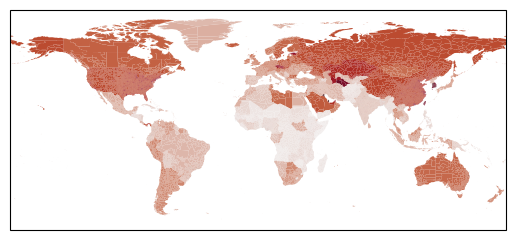

In [51]:
from funcs_plot import plot_map
import cmocean
plot_map((a.sel(gwl=2,hierid=gdf.hierid.values) - 
          a.sel(gwl=0.61,hierid=gdf.hierid.values)),
         gdf,cmap=cmocean.cm.balance,vmin=-30000,vmax=30000)